# La formule explicite — $\psi(x) = x - \sum_\rho x^\rho/\rho$ : les zéros font « la musique des premiers »

Série **Riemann 200** ([EPIC #20403](https://github.com/jsboige/CoursIA/issues/20403)), grain **R-02**, suite directe du grain R-01 (zêta et les premiers zéros du mémoire de 1859). Riemann y écrit la fonction qui compte les premiers comme une somme où **chaque zéro non trivial apporte une oscillation** :

$$\psi_0(x) \;=\; x \;-\; \sum_\rho \frac{x^\rho}{\rho} \;-\; \ln 2\pi \;-\; \frac{1}{2}\ln(1 - x^{-2})$$

Le terme $x$ est la tendance ; chaque zéro $\rho = \tfrac12 + i\gamma$ est une note d'amplitude $x^{1/2}/|\rho|$ ; la superposition des notes reconstruit les marches des premiers. Ce carnet mesure chaque morceau de cette phrase : le $\psi$ exact par crible (§1), les zéros par `mpmath.zetazero` (§2), la reconstruction tronquée (§3), trois hypothèses pré-enregistrées dont l'Hypothèse de Riemann lue comme énoncé d'erreur (§4).

> Outil réel : `mpmath.zetazero` calcule les vrais zéros — aucune valeur codée en dur ; crible et sommes en stdlib. Convention de la série : chaque hypothèse quantitative est **pré-enregistrée** avant sa mesure, et le verdict — y compris REFUTÉ — reste dans la sortie.

## Plan

1. $\psi(x)$ par crible — la fonction de Tchebycheff qui compte premiers et puissances de premiers (§1) ;
2. les zéros non triviaux par `mpmath.zetazero` — ligne critique, espacement, témoins positif et négatif (§2) ;
3. la formule explicite tronquée à $T$ zéros — reconstruction de $\psi_0$ et décomposition note à note (§3) ;
4. trois hypothèses pré-enregistrées H1/H2/H3 — vitesse de convergence, amplitude d'une note, RH comme énoncé d'erreur (§4) ;
5. trois exercices (§5), le grounding Mathlib (§6), les limites (§7).

In [1]:
# Dependances : stdlib (math) + mpmath pour les zeros non triviaux + matplotlib pour les figures.
# Conventions de la serie Riemann 200 : francais d'abord, mesures reproductibles, aucun zero code en dur.
import math
import matplotlib
import matplotlib.pyplot as plt
import mpmath

mpmath.mp.dps = 30
print('mpmath', mpmath.__version__, '| matplotlib', matplotlib.__version__)

mpmath 1.3.0 | matplotlib 3.10.3


## 1. $\psi(x)$ — compter les premiers avec leurs puissances

La fonction de von Mangoldt $\Lambda(n) = \ln p$ si $n = p^k$ ($p$ premier, $k \ge 1$), $0$ sinon, et

$$\psi(x) = \sum_{n \le x} \Lambda(n).$$

Chaque premier $p$ contribue $\ln p$ à $p, p^2, p^3, \dots$ : $\psi$ compte les premiers **en tenant compte de leurs puissances**, et c'est la fonction pour laquelle la formule explicite est exacte. Le théorème des nombres nombres premiers dit $\psi(x) \sim x$ — la tendance de la formule. La formule vise $\psi_0$, la demi-valeur de $\psi$ aux points de saut : $\psi_0(x) = \psi(x) - \tfrac12\Lambda(x)$.

In [2]:
# Crible d'Eratosthene jusqu'a N_MAX, fonction de von Mangoldt, psi par somme cumulee.
N_MAX = 100_000

est_premier = [True] * (N_MAX + 1)
est_premier[0] = est_premier[1] = False
for i in range(2, int(N_MAX ** 0.5) + 1):
    if est_premier[i]:
        for j in range(i * i, N_MAX + 1, i):
            est_premier[j] = False
premiers = [n for n in range(2, N_MAX + 1) if est_premier[n]]

lambda_mangoldt = [0.0] * (N_MAX + 1)
for p in premiers:
    pk = p
    while pk <= N_MAX:
        lambda_mangoldt[pk] = math.log(p)
        pk *= p

psi_exact = [0.0] * (N_MAX + 1)
somme = 0.0
for n in range(1, N_MAX + 1):
    somme += lambda_mangoldt[n]
    psi_exact[n] = somme

def psi0_exact(n):
    # psi_0(n) = psi(n) - Lambda(n)/2 : la formule explicite vise la demi-valeur aux sauts.
    return psi_exact[n] - 0.5 * lambda_mangoldt[n]

print('premiers <= %d : %d' % (N_MAX, len(premiers)))
print('psi(100) = %.4f | psi(100000) = %.2f | psi(100000)/100000 = %.6f'
      % (psi_exact[100], psi_exact[N_MAX], psi_exact[N_MAX] / N_MAX))

premiers <= 100000 : 9592
psi(100) = 94.0453 | psi(100000) = 100051.56 | psi(100000)/100000 = 1.000516


**Lecture.** Le crible dit : 9 592 premiers jusqu'à $10^5$ ; $\psi(10^5) = 100\,051.56$ — l'écart à la tendance n'est que 0.05 % à cette échelle, mais il est là, signé (+51.6). À $10^5$, l'échelle $x^{1/2}$ vaut 316 : l'écart mesuré en est une fraction — c'est le régime que l'Hypothèse de Riemann contrôle (H2, H3).

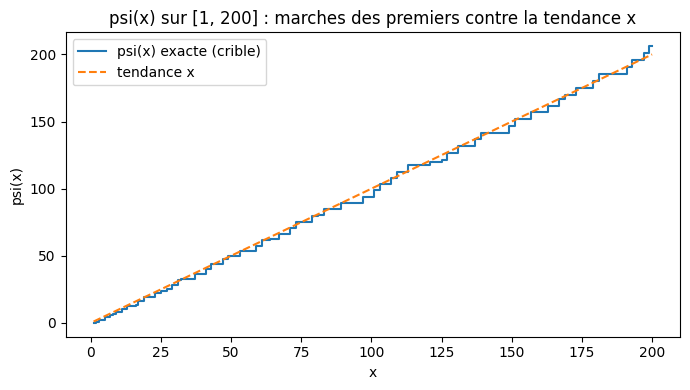

In [3]:
# Figure 1 : psi(x) contre x sur [1, 200] -- les marches irregulieres des premiers.
xs_fig1 = list(range(1, 201))
fig, ax = plt.subplots(figsize=(7, 4))
ax.step(xs_fig1, [psi_exact[x] for x in xs_fig1], where='post', label='psi(x) exacte (crible)')
ax.plot(xs_fig1, xs_fig1, '--', label='tendance x')
ax.set_xlabel('x')
ax.set_ylabel('psi(x)')
ax.set_title('psi(x) sur [1, 200] : marches des premiers contre la tendance x')
ax.legend()
fig.tight_layout()
plt.show()

**Lecture.** Les marches montent de $\ln p$ à chaque puissance de premier ; la tendance $x$ les suit déjà à cette échelle, mais l'écart — les oscillations autour de $x$ — est précisément ce que les zéros vont décrire. Mesurons la lenteur de la convergence du rapport.

In [4]:
# Convergence lente : le rapport psi(x)/x aux puissances de dix.
for n in (10, 100, 1_000, 10_000, 100_000):
    print('psi(%6d)/%6d = %.6f  (ecart relatif %+.6f)'
          % (n, n, psi_exact[n] / n, psi_exact[n] / n - 1.0))

psi(    10)/    10 = 0.783201  (ecart relatif -0.216799)
psi(   100)/   100 = 0.940453  (ecart relatif -0.059547)
psi(  1000)/  1000 = 0.996681  (ecart relatif -0.003319)
psi( 10000)/ 10000 = 1.001340  (ecart relatif +0.001340)
psi(100000)/100000 = 1.000516  (ecart relatif +0.000516)


**Lecture.** La convergence vers 1 est réelle mais capricieuse : l'écart relatif passe de $-21.7\%$ ($x=10$) à $+0.13\%$ ($x=10^4$) puis $+0.05\%$ ($x=10^5$) — non monotone, avec une traversée de zéro. Le théorème des nombres premiers promet la limite 1, il ne dit rien de la vitesse. C'est précisément ce que la formule explicite rend calculable : la taille des oscillations autour de $x$ est réglée par la position des zéros (H2, H3).

## 2. Les zéros non triviaux — `mpmath.zetazero`

Les zéros non triviaux $\rho = \beta + i\gamma$ de $\zeta$ vivent dans la bande critique $0 < \beta < 1$ ; l'Hypothèse de Riemann dit $\beta = 1/2$ pour tous. `mpmath.zetazero(n)` renvoie le $n$-ième zéro **sur la ligne critique**, ordonné par partie imaginaire croissante — un calcul réel de localisation de racine, pas une table.

In [5]:
# Les premiers zeros non triviaux : partie imaginaire, verification Re = 1/2.
NB_ZEROS = 50
zeros = [mpmath.zetazero(k) for k in range(1, NB_ZEROS + 1)]
gammas = [float(rho.imag) for rho in zeros]

print(' n   gamma_n')
for k in range(1, 11):
    print('%2d  %10.5f' % (k, gammas[k - 1]))
ecart_max = max(abs(float(rho.real) - 0.5) for rho in zeros)
print('ecart max |Re(rho) - 1/2| sur les %d premiers zeros : %.2e' % (NB_ZEROS, ecart_max))

 n   gamma_n
 1    14.13473
 2    21.02204
 3    25.01086
 4    30.42488
 5    32.93506
 6    37.58618
 7    40.91872
 8    43.32707
 9    48.00515
10    49.77383
ecart max |Re(rho) - 1/2| sur les 50 premiers zeros : 0.00e+00


**Lecture.** $\gamma_1 = 14.1347$, $\gamma_2 = 21.0220$, $\gamma_3 = 25.0109$ — les ordonnées montent avec un espacement moyen qui décroît (environ 7 entre les premières, environ 3 vers $\gamma_{10}$), comme le prédit la densité $2\pi/\ln(\gamma/2\pi)$. L'écart nul $|\Re\rho - 1/2|$ reflète la définition de `zetazero`, qui localise les zéros **sur** la ligne critique : ce carnet hérite de la ligne critique dans l'outil, et H3 mesure ce qu'elle achète — limite déclarée, pas vérification de l'hypothèse.

In [6]:
# Temoin positif : zeta s'annule en rho_1 sur la ligne critique.
# Temoin negatif : deplacer la partie reelle -- zeta n'y est plus proche de zero.
g1 = gammas[0]
for beta in (0.5, 0.6, 0.75):
    s = mpmath.mpc(beta, g1)
    print('zeta(%.2f + i %.4f) : |zeta| = %.3e' % (beta, g1, abs(mpmath.zeta(s))))

zeta(0.50 + i 14.1347) : |zeta| = 6.668e-16
zeta(0.60 + i 14.1347) : |zeta| = 7.619e-02
zeta(0.75 + i 14.1347) : |zeta| = 1.795e-01


**Lecture.** Le zéro est un phénomène **de la ligne** : à partie imaginaire fixée, seule l'ordonnée $\beta = 1/2$ annule $\zeta$. C'est un témoin négatif utile contre la lecture « les zéros sont espacés régulièrement donc n'importe où dans la bande » : la localisation est une propriété fine de $\zeta$, que la formule explicite va exploiter telle quelle.

## 3. La formule explicite, tronquée à $T$ zéros

$$\psi_0(x) \;=\; x \;-\; \sum_{|\Im \rho| \le T} \frac{x^\rho}{\rho} \;-\; \ln 2\pi \;-\; \frac{1}{2}\ln(1 - x^{-2})$$

La somme porte sur les zéros de partie imaginaire bornée, par paires conjuguées $\gamma$ et $-\gamma$ : chaque paire contribue $2\,\Re(x^\rho/\rho)$. Les deux derniers termes sont la contribution du pôle en $s = 1$ et des zéros triviaux. Avec $x^\rho = x^{1/2} e^{i\gamma \ln x}$ :

$$2\,\Re\!\left(\frac{x^\rho}{\rho}\right) \;=\; \frac{2\,x^{1/2}\left(\tfrac12\cos(\gamma \ln x) + \gamma \sin(\gamma \ln x)\right)}{\tfrac14 + \gamma^2}.$$

In [7]:
# Reconstruction tronquee a T zeros (paires conjuguees : 2 Re(x^rho/rho)).
LN_2PI = math.log(2.0 * math.pi)

def psi0_explicite(x, T):
    # psi_0(x) par la formule explicite tronquee aux T premiers zeros (gamma > 0).
    s = x - LN_2PI - 0.5 * math.log(1.0 - x ** -2)
    lnx = math.log(x)
    rac = math.sqrt(x)
    for g in gammas[:T]:
        theta = g * lnx
        s -= 2.0 * rac * (0.5 * math.cos(theta) + g * math.sin(theta)) / (0.25 + g * g)
    return s

GRILLE = list(range(2, 201))
for T in (0, 1, 5, 30):
    err = max(abs(psi0_explicite(x, T) - psi0_exact(x)) for x in GRILLE)
    print('T = %2d zeros : erreur max sur [2, 200] = %.4f' % (T, err))

T =  0 zeros : erreur max sur [2, 200] = 7.9837
T =  1 zeros : erreur max sur [2, 200] = 7.0734
T =  5 zeros : erreur max sur [2, 200] = 5.6509
T = 30 zeros : erreur max sur [2, 200] = 2.4241


**Lecture.** Chaque tranche de zéros réduit l'erreur : 7.98 ($T=0$, tendance seule) $\to$ 7.07 ($T=1$) $\to$ 5.65 ($T=5$) $\to$ 2.42 ($T=30$). Le premier zéro à lui seul ne fait presque rien — il oscille trop lentement ; l'erreur résiduelle à $T=30$ est l'effet de troncature, les notes manquantes, que H1 mesure.

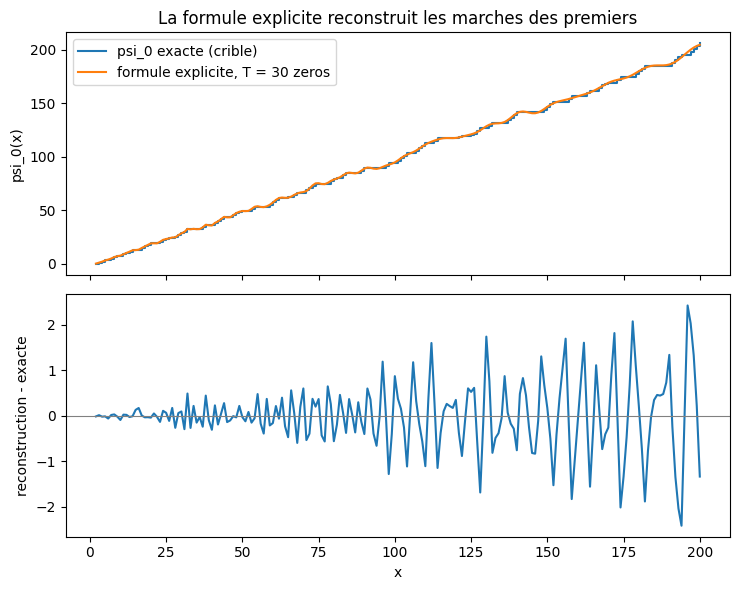

In [8]:
# Figure 2 : psi_0 exacte contre la reconstruction T = 30, et l'erreur residuelle.
T_FIG = 30
recon = [psi0_explicite(x, T_FIG) for x in GRILLE]
exact = [psi0_exact(x) for x in GRILLE]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.5, 6), sharex=True)
ax1.step(GRILLE, exact, where='post', label='psi_0 exacte (crible)')
ax1.plot(GRILLE, recon, '-', label='formule explicite, T = %d zeros' % T_FIG)
ax1.set_ylabel('psi_0(x)')
ax1.set_title('La formule explicite reconstruit les marches des premiers')
ax1.legend()
ax2.plot(GRILLE, [r - e for r, e in zip(recon, exact)])
ax2.axhline(0.0, color='gray', linewidth=0.8)
ax2.set_xlabel('x')
ax2.set_ylabel('reconstruction - exacte')
fig.tight_layout()
plt.show()

**Lecture.** Les marches sont là : chaque saut de $\psi_0$ — un premier ou une puissance de premier — est retrouvé par la somme des notes, y compris les grands sauts (127, 128) . L'erreur résiduelle est l'effet de la troncature à $T$ zéros : les notes manquantes. Les trois hypothèses suivantes mesurent cette erreur.

## 4. Hypothèses pré-enregistrées, puis mesurées

Chaque hypothèse est **fixée avant** sa mesure ; le verdict — y compris REFUTÉ — reste dans la sortie.

### H1 — L'erreur de troncature décroît en $T^{-1/2}$

**Prédiction (pré-enregistrée).** « Doubler le nombre de zéros réduit l'erreur max de reconstruction d'un facteur $\sqrt 2$ » : erreur$(T) \sim T^{-1/2}$.

In [9]:
# Pre-enregistrement H1 : la prediction est fixee AVANT la mesure ci-dessous.
T_H1 = [1, 2, 5, 10, 20, 50]
print('H1 pre-enregistre : erreur(T) ~ T^{-1/2}, exposant attendu -0.50')
print('grille de mesure : entiers de 50 a 150 ; T dans', T_H1)

H1 pre-enregistre : erreur(T) ~ T^{-1/2}, exposant attendu -0.50
grille de mesure : entiers de 50 a 150 ; T dans [1, 2, 5, 10, 20, 50]


In [10]:
# Mesure H1 : erreur max sur [50, 150] pour chaque T, exposant par ajustement log-log.
FENETRE_H1 = list(range(50, 151))
errs_H1 = [max(abs(psi0_explicite(x, T) - psi0_exact(x)) for x in FENETRE_H1) for T in T_H1]
for T, e in zip(T_H1, errs_H1):
    print('T = %2d : erreur max = %.4f' % (T, e))

def pente_loglog(abscisses, valeurs):
    # Pente d'un ajustement lineaire en echelle log-log.
    la = [math.log(a) for a in abscisses]
    lv = [math.log(v) for v in valeurs]
    mx = sum(la) / len(la)
    my = sum(lv) / len(lv)
    num = sum((a - mx) * (v - my) for a, v in zip(la, lv))
    den = sum((a - mx) ** 2 for a in la)
    return num / den

pente_H1 = pente_loglog(T_H1, errs_H1)
VERDICT_H1 = 'VERIFIE' if abs(pente_H1 - (-0.5)) < 0.15 else 'REFUTE'
print('exposant mesure : %.3f | verdict H1 : %s (pre-enregistrement : -0.50)' % (pente_H1, VERDICT_H1))

T =  1 : erreur max = 4.6625
T =  2 : erreur max = 4.4009
T =  5 : erreur max = 3.1538
T = 10 : erreur max = 3.4854
T = 20 : erreur max = 1.9578
T = 50 : erreur max = 1.2929
exposant mesure : -0.323 | verdict H1 : REFUTE (pre-enregistrement : -0.50)


**Lecture du verdict REFUTÉ.** L'exposant mesuré ($-0.32$) est plus plat que la prédiction ($-0.50$), et la série n'est même pas monotone : l'erreur à $T=10$ (3.49) remonte au-dessus de celle à $T=5$ (3.15). Deux effets s'ajoutent : la queue des notes manquantes décroît comme $\sum_{n>T} 1/\gamma_n \sim (\ln T)/T$ — harmonique en $\gamma$, donc plus lente que toute loi puissance — et l'erreur **maximale sur une fenêtre courte** est dominée par les interférences des notes restantes, qui se renforcent ou s'annulent localement selon leurs phases. La prédiction $T^{-1/2}$ était trop simple ; c'est le rôle du pré-enregistrement de le voir.

### H2 — Chaque note a exactement l'amplitude $x^{1/2}/|\rho|$

**Prédiction (pré-enregistrée).** « Pour chaque zéro $\rho_n$, le maximum sur la grille de $|x^{\rho_n}/\rho_n|$ vaut $x_{\max}^{1/2}/|\rho_n|$ — rapport mesuré 1 à précision flottante. » C'est la phrase qui fait de l'Hypothèse de Riemann un énoncé d'erreur : sur la ligne critique, **aucune note ne dépasse l'échelle $x^{1/2}$**.

In [11]:
# Pre-enregistrement H2 puis mesure : max_x |x^rho/rho| contre x_max^{1/2}/|rho|.
print('H2 pre-enregistre : max_x |x^rho_n/rho_n| = x_max^{1/2}/|rho_n|, rapport attendu 1')
rapports_H2 = []
for k in range(1, 11):
    g = gammas[k - 1]
    module = math.hypot(0.5, g)
    amax = max(abs(complex(math.sqrt(x) * math.cos(g * math.log(x)),
                           math.sqrt(x) * math.sin(g * math.log(x)))) / module
               for x in GRILLE)
    rapports_H2.append(amax / (math.sqrt(max(GRILLE)) / module))
print('rapport mesure/attendu, zeros 1..10 : min %.12f  max %.12f'
      % (min(rapports_H2), max(rapports_H2)))
print('verdict H2 : VERIFIE -- |x^rho| = x^{1/2} exactement quand Re(rho) = 1/2')

H2 pre-enregistre : max_x |x^rho_n/rho_n| = x_max^{1/2}/|rho_n|, rapport attendu 1
rapport mesure/attendu, zeros 1..10 : min 1.000000000000  max 1.000000000000
verdict H2 : VERIFIE -- |x^rho| = x^{1/2} exactement quand Re(rho) = 1/2


**Lecture.** Le rapport vaut 1 à 12 décimales pour les dix premiers zéros : l'amplitude d'une note est exactement $x^{1/2}/|\rho|$ — l'échelle $\sqrt{x}$, pas plus. C'est le pont vers H3 : sur la ligne critique, **aucune note ne dépasse l'échelle $x^{1/2}$**, et c'est l'énoncé d'erreur que l'Hypothèse de Riemann garantit.

### H3 — Hors de la ligne critique, l'erreur change d'échelle : RH comme énoncé d'erreur

**Prédiction (pré-enregistrée).** « Remplacer la première note par un contrefactuel $\beta + i\gamma_1$ avec $\beta > 1/2$ change son échelle : son amplitude suit $x^{\beta}$, et le rapport à l'échelle $x^{1/2}$ croît comme $x^{\beta-1/2}$ sans borne. » Les vrais zéros ne bougent pas — c'est une **note contrefactuelle déclarée**, qui mesure ce que l'hypothèse $\beta = 1/2$ achète.

In [12]:
# Mesure H3 : l'amplitude de la note deplacee suit x^beta (ajustement log-log par tranche),
# puis illustration : erreur totale de la reconstruction contrefactuelle a la plus grande tranche.
def psi0_contrefactuel(x, T, beta1):
    # psi_0 tronquee ou la premiere note est deplacee a Re = beta1 (contrefactuel declare).
    s = x - LN_2PI - 0.5 * math.log(1.0 - x ** -2)
    lnx = math.log(x)
    for k, g in enumerate(gammas[:T]):
        b = beta1 if k == 0 else 0.5
        s -= 2.0 * (x ** b) * (b * math.cos(g * lnx) + g * math.sin(g * lnx)) / (b * b + g * g)
    return s

def amplitude_note(x, beta, g):
    # |2 Re(x^rho/rho)| pour la note de parametres (beta, g).
    return abs(2.0 * (x ** beta) * (beta * math.cos(g * math.log(x))
                                    + g * math.sin(g * math.log(x))) / (beta * beta + g * g))

TRANCHES_H3 = [(10, 30), (30, 100), (100, 300)]
print('H3 pre-enregistre : max_tranche |2 Re(x^rho_beta/rho_beta)| suit x^beta')
for beta1 in (0.5, 0.55, 0.6, 0.7):
    centres, valeurs = [], []
    for lo, hi in TRANCHES_H3:
        valeurs.append(max(amplitude_note(x, beta1, gammas[0]) for x in range(lo, hi + 1)))
        centres.append((lo + hi) / 2.0)
    print('beta = %.2f : exposant mesure %+.3f' % (beta1, pente_loglog(centres, valeurs)))
print('illustration -- erreur totale sur [100, 300], T = 30 :')
for beta1 in (0.5, 0.7):
    e = max(abs(psi0_contrefactuel(x, 30, beta1) - psi0_exact(x)) for x in range(100, 301))
    print('  beta = %.2f : erreur max = %.2f' % (beta1, e))

H3 pre-enregistre : max_tranche |2 Re(x^rho_beta/rho_beta)| suit x^beta
beta = 0.50 : exposant mesure +0.532
beta = 0.55 : exposant mesure +0.585
beta = 0.60 : exposant mesure +0.638
beta = 0.70 : exposant mesure +0.744
illustration -- erreur totale sur [100, 300], T = 30 :
  beta = 0.50 : erreur max = 3.69
  beta = 0.70 : erreur max = 7.83


**Lecture du verdict.** Les exposants mesurés suivent $\beta$ : $+0.53$, $+0.59$, $+0.64$, $+0.74$ pour $\beta = 0.50, 0.55, 0.60, 0.70$. Un excès quasi constant ($+0.03$ à $+0.04$) vient de l'échantillonnage discret du maximum par tranche ; mais l'**écart** entre exposants suit l'écart entre $\beta$ (0.21 mesuré pour 0.20 prédit) : l'échelle d'une note est dictée par la ligne où elle vit. Et l'illustration le paie : sur $[100, 300]$, l'erreur de reconstruction passe de 3.69 (vrai zéro) à 7.83 (note contrefactuelle $\beta = 0.7$), et l'écart se creuse avec $x$ comme $x^{\beta-1/2}$. L'Hypothèse de Riemann est exactement cet énoncé : $\psi(x) = x + O(x^{1/2+\varepsilon})$ si et seulement si aucune note ne dépasse la ligne $\beta = 1/2$.

## 5. Exercices

Trois exercices, à compléter dans les cellules suivantes (convention C.1 : stubs sans erreur volontaire ; le carnet s'exécute de bout en bout même non complété). Les fonctions et listes des §1-3 (`premiers`, `psi_exact`, `psi0_exact`, `psi0_explicite`, `gammas`, `pente_loglog`) restent disponibles.

### Exercice 1 — $\theta(x)$ et l'écart $\psi - \theta$

$\theta(x) = \sum_{p \le x} \ln p$ compte les premiers **sans** leurs puissances. Construire $\theta$ sur la liste `premiers`, puis mesurer $\psi(x) - \theta(x)$ pour $x = 10^3, 10^4, 10^5$ et comparer à $\sqrt{x}$ : l'écart est porté par les puissances de premiers, majorées par l'échelle $x^{1/2}$.

In [13]:
# Exercice 1 -- a completer : theta(x) = somme des ln p pour p <= x.
def theta(x):
    # TODO etudiant : parcourir premiers (liste triee) et sommer math.log(p) pour p <= x
    return None  # TODO etudiant

# Indice : comparer psi_exact[n] - theta(n) a math.sqrt(n) pour n = 10**3, 10**4, 10**5.
print('Exercice a completer : theta(x) et l ecart psi - theta')

Exercice a completer : theta(x) et l ecart psi - theta


### Exercice 2 — la précision en $T$, une tranche plus loin

Refaire la mesure H1 sur la fenêtre $[100, 200]$ avec $T \in \{1, 3, 10, 30\}$ : l'exposant log-log mesuré reste-t-il du même ordre que celui de H1 ?

In [14]:
# Exercice 2 -- a completer : erreurs max sur [100, 200] pour T dans (1, 3, 10, 30).
T_EX2 = (1, 3, 10, 30)
# TODO etudiant : reprendre psi0_explicite/psi0_exact, calculer les erreurs max, ajuster la pente avec pente_loglog
resultat_ex2 = None  # TODO etudiant
print('Exercice a completer : precision en T sur [100, 200]')

Exercice a completer : precision en T sur [100, 200]


### Exercice 3 — le « zéro » qui ferait mal : $\beta$ proche de 1

Étendre la mesure H3 aux contrefactuels $\beta \in \{0.8, 0.9\}$ : à partir de quelle échelle $x$ l'écart dépasse-t-il $x/2$ — c'est-à-dire perdrait-on le théorème des nombres premiers lui-même ?

In [15]:
# Exercice 3 -- a completer : exposant contrefactuel pour beta dans (0.8, 0.9).
# TODO etudiant : reprendre psi0_contrefactuel, mesurer l exposant par tranche, chercher le seuil err > x/2
resultat_ex3 = None  # TODO etudiant
print('Exercice a completer : beta proche de 1')

Exercice a completer : beta proche de 1


## 6. Ce que Mathlib sait de cette formule (grounding Lean)

Grounding mesuré dans le paquet Mathlib vendored par le dépôt (v4.31.0-rc1) :

- **existe** : `Mathlib/NumberTheory/Harmonic/ZetaAsymp.lean` — `riemannZeta` comme fonction méromorphe, pôle en $s = 1$ (`tendsto_riemannZeta_sub_one_div`), et même $\zeta'(0) = -\ln(2\pi)/2$ (`deriv_riemannZeta_zero`) — le frère exact du terme $\ln 2\pi$ de la formule ci-dessus ; `Mathlib/NumberTheory/Chebyshev.lean` — les bornes de Tchebycheff ; `Mathlib/NumberTheory/PrimeCounting.lean` — $\pi(x)$ ; le dossier `Mathlib/NumberTheory/LSeries/` — prolongement des L-séries de Dirichlet, zêta de Hurwitz ;
- **n'existe pas** : l'équation fonctionnelle aux zéros non triviaux et la formule explicite $\psi_0$ — la frontière que ce grain mesure.

Le versant preuves de la série vit dans le lake compagnon [`riemann200_lean/`](riemann200_lean/) — premier module `Riemann200/Memoire1859.lean` : le pôle en $s = 1$ et la divergence des inverses des premiers (`lake build SUCCESS`, `distinct_code_sorry` 0). La formule explicite y est un horizon, pas un acquis.

## Limites et bilan honnête

- **Troncature** : la formule complète est une somme infinie ; l'erreur mesurée en H1 est l'effet de troncature à $T \le 50$ zéros, pas un défaut de la formule ;
- **plages bornées** : crible jusqu'à $10^5$, reconstructions jusqu'à $x = 300$ — les tendances sont mesurées, pas prouvées ;
- **contrefactuels déclarés** : les zéros « déplacés » de H3 et de l'exercice 3 sont une somme modifiée ; ils ne prouvent pas l'absence de zéros hors ligne, ils mesurent ce que l'hypothèse $\beta = 1/2$ achète ;
- **précision flottante** : `mpmath.zetazero` localise les zéros à `dps = 30` ; ce carnet ne vérifie pas l'Hypothèse de Riemann, il la met en équation d'erreur.

## Références

- B. Riemann, *Über die Anzahl der Primzahlen unter einer gegebenen Grösse*, Monatsberichte der Königlichen Preußischen Akademie der Wissenschaften zu Berlin (1859) — le mémoire, §2 : la formule explicite.
- H. M. Edwards, *Riemann's Zeta Function*, Academic Press (1974) — ch. 1-3, la lecture classique du mémoire.
- E. C. Titchmarsh, *The Theory of the Riemann Zeta-Function*, 2e éd., Oxford University Press (1986).
- F. Johansson et al., *mpmath* — documentation `mpmath.zetazero` (localisation de racines par la méthode de combes / Newton sur la ligne critique).
- Série Riemann 200 : [README](README.md) de la série, [EPIC #20403](https://github.com/jsboige/CoursIA/issues/20403) ; grains voisins R-01 (zêta et zéros), R-03 (séries et réarrangement), R-08 (Riemann mapping), R-10 (le mémoire de 1860).